Language: **English (default)** | [Polski](examples.ipynb)

# Lecture 01 -- experiment: linear regression from scratch

Companion material to [`lecture.en.md`](lecture.en.md). We implement the
mechanism described in the lecture: synthetic data -> linear model as
tensors with `requires_grad=True` -> MSE loss -> gradient (hand-derived
formula vs. `autograd`) -> training loop -> visualization.

The true parameters (`a_true`, `b_true`) are the same as in the worked
example from the lecture (`y = 2x + 1`), so the results can be compared.

In [1]:
import matplotlib.pyplot as plt
import torch

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


## 1. Synthetic data

We generate $N$ points $x_i \sim \text{Uniform}(-3, 3)$ and
$y_i = a_{\text{true}} x_i + b_{\text{true}} + \varepsilon_i$, where
$\varepsilon_i$ is Gaussian noise. We create the data on CPU and then move
it to the chosen `device` -- this is the pattern that will work identically
once the data is much larger.

x.shape=(80,), y.shape=(80,), dtype=torch.float32, device=cpu


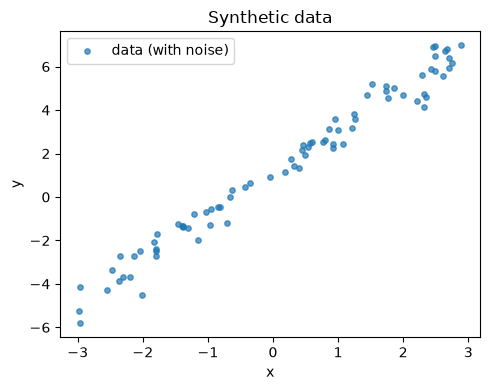

In [2]:
N = 80
a_true, b_true = 2.0, 1.0
noise_std = 0.6

x = torch.empty(N).uniform_(-3, 3)
noise = torch.randn(N) * noise_std
y = a_true * x + b_true + noise

x = x.to(device)
y = y.to(device)

print(f"x.shape={tuple(x.shape)}, y.shape={tuple(y.shape)}, dtype={x.dtype}, device={x.device}")

plt.figure(figsize=(5, 4))
plt.scatter(x.cpu(), y.cpu(), s=15, alpha=0.7, label="data (with noise)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Synthetic data")
plt.legend()
plt.tight_layout()
plt.show()

## 2. Model parameters

The parameters $w$ and $b$ are tensors with `requires_grad=True` -- this is
what sets them apart from plain data: PyTorch will track operations on them
so it can compute the loss's gradient with respect to them when
`.backward()` is called.

In [3]:
w = torch.zeros(1, requires_grad=True, device=device)
b = torch.zeros(1, requires_grad=True, device=device)
print(f"w={w.item():.4f}, b={b.item():.4f}, requires_grad(w)={w.requires_grad}")

w=0.0000, b=0.0000, requires_grad(w)=True


## 3. One step "on paper": autograd vs. the hand-derived formula

Before running the full loop, let's verify that `loss.backward()` computes
exactly what we derived in the lecture:

$$\frac{\partial L}{\partial w} = \frac{2}{N}\sum_i (\hat{y}_i - y_i) x_i,
\qquad
\frac{\partial L}{\partial b} = \frac{2}{N}\sum_i (\hat{y}_i - y_i)$$

In [4]:
y_pred = w * x + b
loss = torch.mean((y_pred - y) ** 2)
loss.backward()

grad_w_autograd = w.grad.clone()
grad_b_autograd = b.grad.clone()

with torch.no_grad():
    error = y_pred - y
    grad_w_manual = (2.0 / N) * torch.sum(error * x)
    grad_b_manual = (2.0 / N) * torch.sum(error)

print(f"loss (w=0, b=0):         {loss.item():.4f}")
print(f"dL/dw  autograd={grad_w_autograd.item(): .4f}   formula={grad_w_manual.item(): .4f}")
print(f"dL/db  autograd={grad_b_autograd.item(): .4f}   formula={grad_b_manual.item(): .4f}")

assert torch.allclose(grad_w_autograd, grad_w_manual.reshape(1), atol=1e-4)
assert torch.allclose(grad_b_autograd, grad_b_manual.reshape(1), atol=1e-4)
print("OK: the autograd gradient matches the formula derived in the lecture.")

w.grad.zero_()
b.grad.zero_()

loss (w=0, b=0):         14.3581
dL/dw  autograd=-12.7047   formula=-12.7047
dL/db  autograd=-2.9173   formula=-2.9173
OK: the autograd gradient matches the formula derived in the lecture.


tensor([0.])

## 4. Full training loop

We start from $w = 0$, $b = 0$ (as in the lecture's worked example) and
repeat: *forward -> loss -> backward -> update* -- without `nn.Module` and
without `optim`, so the mechanism stays visible line by line.

In [5]:
w = torch.zeros(1, requires_grad=True, device=device)
b = torch.zeros(1, requires_grad=True, device=device)

learning_rate = 0.05
n_epochs = 200
snapshot_epochs = {0, 5, 20, 100, n_epochs - 1}

loss_history = []
snapshots = []

for epoch in range(n_epochs):
    y_pred = w * x + b
    loss = torch.mean((y_pred - y) ** 2)

    loss.backward()
    with torch.no_grad():
        w -= learning_rate * w.grad
        b -= learning_rate * b.grad
    w.grad.zero_()
    b.grad.zero_()

    loss_history.append(loss.item())
    if epoch in snapshot_epochs:
        snapshots.append((epoch, w.item(), b.item()))

print(f"Start: a_true={a_true}, b_true={b_true}")
print(f"End:   w={w.item():.4f}, b={b.item():.4f}, final loss={loss_history[-1]:.4f}")

Start: a_true=2.0, b_true=1.0
End:   w=1.9635, b=1.0873, final loss=0.2990


## 5. Visualization: fit and loss curve

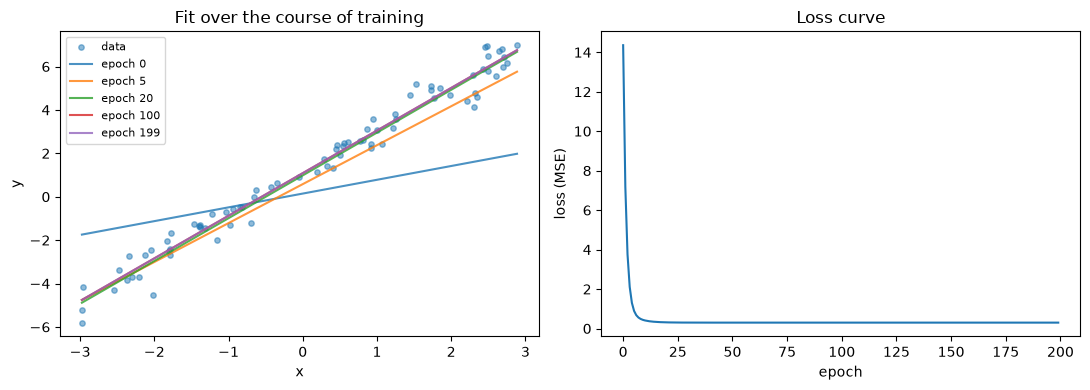

In [6]:
x_cpu = x.cpu()
y_cpu = y.cpu()
x_line = torch.linspace(x_cpu.min(), x_cpu.max(), 100)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(x_cpu, y_cpu, s=15, alpha=0.5, label="data")
for epoch, w_snap, b_snap in snapshots:
    axes[0].plot(
        x_line, w_snap * x_line + b_snap,
        label=f"epoch {epoch}", alpha=0.8,
    )
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].set_title("Fit over the course of training")
axes[0].legend(fontsize=8)

axes[1].plot(loss_history)
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("loss (MSE)")
axes[1].set_title("Loss curve")

plt.tight_layout()
plt.show()

## 6. What happens when $\eta$ is too large?

The same code, the only difference is `learning_rate`. Watch the loss
curve.

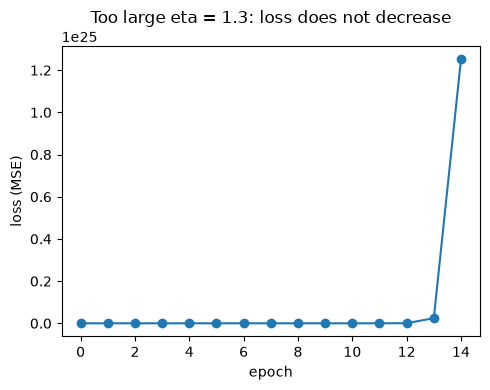

First 5 loss values: ['14.36', '685.46', '35248.12', '1818082.62', '93788248.00']
Last 5 loss values: ['1767558812455141376.00', '91182481699277635584.00', '4703800956355763765248.00', '242653515577158096912384.00', '12517690744787223724425216.00']


In [7]:
w_big_lr = torch.zeros(1, requires_grad=True, device=device)
b_big_lr = torch.zeros(1, requires_grad=True, device=device)

learning_rate_too_big = 1.3
n_epochs_demo = 15
loss_history_big_lr = []

for epoch in range(n_epochs_demo):
    y_pred = w_big_lr * x + b_big_lr
    loss = torch.mean((y_pred - y) ** 2)

    loss.backward()
    with torch.no_grad():
        w_big_lr -= learning_rate_too_big * w_big_lr.grad
        b_big_lr -= learning_rate_too_big * b_big_lr.grad
    w_big_lr.grad.zero_()
    b_big_lr.grad.zero_()

    loss_history_big_lr.append(loss.item())

plt.figure(figsize=(5, 4))
plt.plot(loss_history_big_lr, marker="o")
plt.xlabel("epoch")
plt.ylabel("loss (MSE)")
plt.title(f"Too large eta = {learning_rate_too_big}: loss does not decrease")
plt.tight_layout()
plt.show()

print("First 5 loss values:", [f"{v:.2f}" for v in loss_history_big_lr[:5]])
print("Last 5 loss values:", [f"{v:.2f}" for v in loss_history_big_lr[-5:]])

## Summary

- The gradient from `autograd` matches the formula derived by hand in the
  lecture -- this isn't a different procedure, it's the same mathematics.
- The loss converges to the level set by the noise in the data (not to
  zero).
- With too large an $\eta$, the same code leads to divergence -- the
  hyperparameter decides whether the mechanism works at all.

Discussion questions and bibliography: see [`lecture.en.md`](lecture.en.md).